# Getting Started with CodeCarbon and EcoLogits

**Measuring the energy and emissions of Python programs**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/seankellyhp/eco-measure-amsterdam/blob/main/notebooks/getting-started.ipynb)

In [1]:
# Setup. On Colab: install the packages Colab does not have, and download the data.
# Locally (uv sync), everything is already installed and in the repository.
import os
import sys
import urllib.request
import warnings
from pathlib import Path

if "google.colab" in sys.modules:
    # Colab's GPU runtime has cudf-polars, which needs an older polars; these notebooks do not use it.
    %pip uninstall -q -y cudf-polars-cu13 cudf-polars-cu12
    %pip install -q -U codecarbon "ecologits[openai]" polars plotnine

# The notebooks read the data from ../data, the data folder of the repository.
for file in ["data/austen_books.csv", "data/bing.csv"]:
    path = Path("..") / file
    if not path.exists():
        path.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/seankellyhp/eco-measure-amsterdam/main/{file}", path)

# Quieten CodeCarbon before the first tracker is created.
os.environ["CODECARBON_LOG_LEVEL"] = "error"
warnings.filterwarnings("ignore")

import plotnine
import polars as pl

plotnine.options.figure_size = (7, 3.5)
plotnine.options.dpi = 110
pl.Config.set_tbl_hide_dataframe_shape(True)

polars.config.Config

## Description

This tutorial measures and compares the resource use of Python programs. This
is relevant because of the increased reliance of social science research on
computationally complex machine learning and AI methods such as large
language models (Balluff et al., 2026), which may consume significantly more
non-renewable resources than computationally less advanced methods
(Hamilton-Palicki et al., 2026; Luccioni et al., 2024).

It uses two open source Python libraries directly:
[CodeCarbon](https://codecarbon.io) (Courty et al., 2026), for measuring
the energy of local programs, and [EcoLogits](https://ecologits.ai)
(Rincé & Banse, 2025), for estimating the energy use of API calls to LLM
providers. Based on measuring time, energy, location, and, in the case of API
calls, the length of LLM responses, they provide estimates for equivalent
carbon emissions, and water use needed to run the program. It is the Python
counterpart of the TidyCarbon tutorial (Hamilton-Palicki & Bravo, 2026),
which does the same analysis in R through a tidy interface over these two
libraries.

## Use Cases

- Track and report time, energy, carbon emissions, and water usage for
  computational analysis tasks.
- Track at macro and micro levels of a program: track a complete analysis, or
  track a pipeline step by step.
- Compare speed and energy use for alternative methods of analysis (e.g.
  different methods of sentiment analysis), providing data for reducing the
  computational effort and emissions of analyses.
- Estimate the energy use and emissions of LLM-based analyses on remote
  servers (OpenAI, Anthropic, Mistral).

## Important Functions

CodeCarbon tracks a whole script, a block of code, or each step of a
pipeline. EcoLogits estimates a single request to a hosted model.

### Function List

| Function | Purpose |
|----|----|
| `OfflineEmissionsTracker()` | Create a local tracker. Reads the machine’s energy counters where it can (RAPL for the CPU, NVML for an NVIDIA GPU), and estimates the energy from the machine’s specs where it cannot. See CodeCarbon for the methodology. |
| `llm_impacts()` | Estimate the impact of a request to an LLM provider. See EcoLogits for the methodology. |
| `tracker.start()` | Begin tracking energy. Place before the code to measure. |
| `tracker.stop()` | End tracking energy. Place after the code to measure. |
| `with OfflineEmissionsTracker() as tracker:` | Measure a block of code, such as a single function call. |
| `tracker.start_task()`, `tracker.stop_task()` | Measure one step of a pipeline, under a label of its own. |
| `carbon_bench()` | Directly compare the emissions of functions. Not part of CodeCarbon: it is written in this tutorial, from tasks. |
| `tracker.final_emissions_data` | The measurement of a tracker, once stopped. |

# Requirements and Installation

There are two ways to run this notebook. Either way, run the setup cell at
the top first, then the cells in order, from top to bottom.

- **Google Colab.** Open the notebook with the *Open in Colab* button above.
  The setup cell installs CodeCarbon, EcoLogits, polars and plotnine
  (scikit-learn, SciPy, NLTK, pyarrow, transformers and PyTorch are already
  on Colab), and downloads the data.

- **Your own machine.** Clone the
  [repository](https://github.com/seankellyhp/eco-measure-amsterdam). It has
  the data and a [uv](https://docs.astral.sh/uv/) environment with every
  package:

  ``` bash
  git clone https://github.com/seankellyhp/eco-measure-amsterdam
  cd eco-measure-amsterdam
  uv sync
  uv run jupyter lab --config jupyter_server_config.py
  ```

polars holds the data and the measurements, and plotnine draws them.
scikit-learn (Pedregosa et al., 2011) fits the topic model, and NLTK
(Bird et al., 2009) provides the stop words, the word and sentence tokenizers and the
VADER sentiment analyzer. transformers (Wolf et al., 2020) and
PyTorch run a sentiment model locally, and openai and pydantic send the
requests to the hosted language model.

On Colab, CodeCarbon measures a shared virtual machine in a Google
data center. It usually cannot read the CPU’s energy counters there, so it
estimates the energy from the CPU model instead.

The data are in the `data` folder of the repository (on Colab, the setup cell downloads them):
`data/austen_books.csv` has one row per printed line of Jane Austen’s six
novels, and `data/bing.csv` is the Bing sentiment lexicon. Both were exported
from the R packages janeaustenr and tidytext by `data/make_data.R`, so the
data are the same as in the R tutorial.

## How to Use

### Initialize local tracking

The following examples demonstrate tracking the resources needed for
computation on a local system. Importantly, measurements are made at the level
of the machine. For accurate comparisons, ensure that no other compute- or
memory-intensive programs (e.g. browsers, long-running analysis tasks) are
running.

In [2]:
from codecarbon import OfflineEmissionsTracker

tracker = OfflineEmissionsTracker(
    project_name="Hello_World",
    output_dir="codecarbon_results",
    country_iso_code="DEU",
    log_level="error",
)

This creates a tracker. It measures nothing until it is started.

The project will be called `Hello_World` in the rows of the log. Each
measurement is appended to `codecarbon_results/emissions.csv`, which is
therefore the source of truth for all tracking done in the project.

`log_level="error"` quietens CodeCarbon, which otherwise prints a progress
line for every reading. Leave it out once to see which measurement method
CodeCarbon found for your hardware.

`EmissionsTracker` looks up the country the machine is in, with one request
to a geolocation service, to estimate the carbon intensity of its
electricity. `OfflineEmissionsTracker` with `country_iso_code` skips that
request.

Carbon intensity is the relationship between energy and the estimated amount
of carbon emitted to generate that electricity. It depends on the
sustainability of local power grids and varies greatly, as Figure 1 shows.
Countries such as France have a low carbon intensity because they generate a
higher proportion of their electricity from low-carbon sources (nuclear,
solar). In contrast, Germany and the US generate a higher proportion from
fossil fuels (coal, gas).

![Figure 1. Carbon intensity of electricity across Europe. Green is low, yellow to brown is higher, and grey has no data. Source: Electricity Maps.](https://raw.githubusercontent.com/seankellyhp/eco-measure-amsterdam/main/figures/electricity-map.png)

Figure 1. Carbon intensity of electricity across Europe. Green is low, yellow to brown is higher, and grey has no data. Source: Electricity Maps.

### Basic measurements of a Python program

We will demonstrate a standard text analysis, using examples from the
[Tidy Text Mining](https://www.tidytextmining.com) book (Silge & Robinson, 2017).

#### Load packages and data

We load the libraries and the Austen books.

In [3]:
import sys
import tempfile
from pathlib import Path

import nltk
import polars as pl
from codecarbon import OfflineEmissionsTracker
from plotnine import aes, coord_flip, geom_col, geom_point, ggplot, labs
from scipy.sparse import csr_matrix

# more advanced analyses downstream
from sklearn.decomposition import LatentDirichletAllocation

In [4]:
austen_books = pl.read_csv("../data/austen_books.csv").with_columns(
    pl.col("text").fill_null("")
)

The stop words are NLTK’s standard English list, and NLTK’s word tokenizer
splits text into words (Bird et al., 2009). NLTK’s
lists, lexicons and tokenizer models are data of their own, which NLTK
downloads once. Here they go into one of the folders NLTK searches:

In [5]:
nltk.download(
    ["stopwords", "punkt_tab"],
    download_dir=f"{sys.prefix}/nltk_data",
    quiet=True,
)

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

stop_words = pl.DataFrame({"word": stopwords.words("english")})

Each tracker in this tutorial is created with the same settings, so keep them
in one place. A temporary folder holds the log here; use a folder of your own
to keep it after the session ends:

In [6]:
log_dir = Path(tempfile.mkdtemp(prefix="codecarbon_results_"))

tracker_args = dict(output_dir=log_dir, country_iso_code="DEU", log_level="error")

Splitting text into words is needed several times below, so it gets a
function of its own:

In [7]:
def unnest_tokens(data, column):
    """Split text into words, one row each, like tidytext's unnest_tokens().

    NLTK's word tokenizer finds the words, which are then lower-cased.
    Tokens with no letter or digit in them (punctuation) are dropped, and
    so are the "'s" and "n't" that the tokenizer splits off words.
    """
    return (
        data
        .with_columns(
            pl.col(column)
            .map_elements(word_tokenize, return_dtype=pl.List(pl.String)).alias("word")
        )
        .drop(column)
        .explode("word")
        .with_columns(pl.col("word").str.to_lowercase())
        .filter(
            pl.col("word").str.contains(r"[\p{L}\p{N}]"),
            ~pl.col("word").is_in(["'s", "n't"]),
        )
    )

For the first example, we start the tracker before a pipeline that counts the
top words in Austen’s novels, and stop it afterwards. It is as simple as
placing the tracker before and after existing code.

#### Tracker start and stop

In [8]:
tracker = OfflineEmissionsTracker(project_name="clean and count words", **tracker_args)
tracker.start()  # Start tracker

books = austen_books.with_columns(
    linenumber=pl.int_range(1, pl.len() + 1).over("book"),
    chapter=pl.col("text").str.contains(r"(?i)^chapter [\divxlc]").cum_sum().over("book"),
)

word_counts = (
    unnest_tokens(books, "text")
    .join(stop_words, on="word", how="anti")
    .group_by("book", "word")
    .len("n")
    .sort("n", descending=True)
)

tracker.stop()  # End tracker

word_counts

book,word,n
str,str,u32
"""Emma""","""mr.""",985
"""Mansfield Park""","""fanny""",925
"""Emma""","""emma""",860
"""Mansfield Park""","""could""",857
"""Emma""","""could""",836
…,…,…
"""Pride & Prejudice""","""enemies""",1
"""Mansfield Park""","""snug""",1
"""Pride & Prejudice""","""42""",1


#### Output data

Every measurement is an object with one attribute per measure and per piece
of machine information. As a side effect, it is automatically appended to the
CSV file in the log folder.

`tracker.final_emissions_data` is now the carbon measurement. Turn it into a
one-row table. It has all of the columns returned by CodeCarbon, most of
which are not needed for downstream analysis. `glimpse()` shows all of them:

In [9]:
books_emit = pl.DataFrame([vars(tracker.final_emissions_data)])

books_emit.glimpse()

Rows: 1
Columns: 38
$ timestamp                <str> '2026-11-09T12:25:32'
$ project_name             <str> 'clean and count words'
$ run_id                   <str> '1eab3be2-fda9-4de3-87cf-f5bb56faa49a'
$ experiment_id            <str> '5b0fa12a-3dd7-45bb-9766-cc326314d9f1'
$ duration                 <f64> 9.083072448998792
$ emissions                <f64> 7.704004673996754e-05
$ emissions_rate           <f64> 8.481716640767244e-06
$ cpu_power                <f64> 17.767137205394015
$ gpu_power                <f64> 11.839747669234843
$ ram_power                <f64> 20.0
$ cpu_energy               <f64> 9.228689244056634e-05
$ gpu_energy               <f64> 5.958782544801533e-05
$ ram_energy               <f64> 5.03566687499996e-05
$ energy_consumed          <f64> 0.00020223138663858127
$ water_consumed           <f64> 0.0
$ country_name             <str> 'Germany'
$ country_iso_code         <str> 'DEU'
$ region                  <null> null
$ cloud_provider           <str> ''
$ cloud_

The results include estimates of time, hardware-level energy consumption,
aggregated energy consumption and an estimate of emissions. `duration` is in
seconds, `energy_consumed` in kWh and `emissions` in kgCO2eq. For a task this
small, the time and energy needs are very small, so watt-hours and milligrams
are easier to read:

In [10]:
emissions = books_emit.select(
    "run_id",
    "project_name",
    "duration",
    cpu_wh=pl.col("cpu_energy") * 1000,
    gpu_wh=pl.col("gpu_energy") * 1000,
    ram_wh=pl.col("ram_energy") * 1000,
    total_wh=pl.col("energy_consumed") * 1000,
    co2e_mg=pl.col("emissions") * 1e6,
    water_consumed="water_consumed",
)

emissions

run_id,project_name,duration,cpu_wh,gpu_wh,ram_wh,total_wh,co2e_mg,water_consumed
str,str,f64,f64,f64,f64,f64,f64,f64
"""1eab3be2-fda9-4de3-87cf-f5bb56…","""clean and count words""",9.083072,0.092287,0.059588,0.050357,0.202231,77.040047,0.0


The selected columns:

| Column | Unit | Description |
|----|----|----|
| `run_id` |  | Unique ID of the tracker run. |
| `project_name` |  | Label given to the tracker. |
| `duration` | seconds | Elapsed time of the task. |
| `cpu_wh` | Wh | Energy used by the CPU. |
| `gpu_wh` | Wh | Energy used by the GPU. |
| `ram_wh` | Wh | Energy used by the RAM. |
| `total_wh` | Wh | Total energy: CPU, GPU and RAM. |
| `co2e_mg` | mgCO2eq | Estimated emissions: energy times the carbon intensity of the grid. |
| `water_consumed` | litres | Estimated water use. It is 0 for a local machine, which has no water use set. |

This level of analysis is useful for reporting and requires the least effort.
Reporting is a very important part of understanding the environmental impacts
of computational methods. However, as this example shows, emissions tracking
is less meaningful for relatively “simple” computational methods such as basic
transformations of data and counting tasks.

Efficiency becomes more relevant with big data, machine learning and AI.
Computational costs are related to the time and memory needed to complete a
task. Tasks that are more computationally complex consume more resources.

### Tracking the efficiency of specific tasks

Now we will take the same data and do a more complex analysis. Counting and
joining are cheap. Fitting a model is not. This stage treats each chapter as a
document and asks latent Dirichlet allocation for six topics, one per novel.
We are interested in the computational needs of fitting a topic model, not
the topics themselves.

scikit-learn’s `LatentDirichletAllocation` needs a document-term matrix, so
the pipeline is: label the chapters, tokenize, drop stop words, count words
per chapter, cast to a matrix, fit. To see what each step in this pipeline
costs, run each one as a **task** of one tracker. `tracker.start_task()` opens
a task under a label describing it and `tracker.stop_task()` closes it. There
is no `tracker.start()` here: the tasks do the starting. `tracker.stop()`
goes in a `finally`, so the tracker is closed and the log written even if a
step fails:

In [11]:
tracker = OfflineEmissionsTracker(project_name="topic model", **tracker_args)

try:
    tracker.start_task("label chapters")
    chapters = books.filter(pl.col("chapter") > 0).select(
        document=pl.format("{}_{}", "book", "chapter"), text="text"
    )
    tracker.stop_task()

    tracker.start_task("tokenize chapters")
    words = unnest_tokens(chapters, "text")
    tracker.stop_task()

    tracker.start_task("remove stop words")
    words = words.join(stop_words, on="word", how="anti")
    tracker.stop_task()

    tracker.start_task("count by chapter")
    counts = words.group_by("document", "word").len("n")
    tracker.stop_task()

    tracker.start_task("cast to dtm")
    counts = counts.with_columns(
        row=pl.col("document").rank("dense") - 1,
        col=pl.col("word").rank("dense") - 1,
    )
    n, row, col = (counts[name].to_numpy() for name in ["n", "row", "col"])
    dtm = csr_matrix((n, (row, col)))
    tracker.stop_task()

    tracker.start_task("LDA")
    lda = LatentDirichletAllocation(n_components=6, random_state=1234).fit(dtm)
    tracker.stop_task()
finally:
    tracker.stop()

`lda` is the fitted model, exactly as the plain pipeline would return it. Its
eight most likely words per topic:

In [12]:
vocabulary = counts["word"].unique().sort()

for topic, weights in enumerate(lda.components_, start=1):
    print(topic, " ".join(vocabulary.gather(weights.argsort()[::-1][:8])))

1 catherine tilney would isabella could morland miss thorpe
2 could would mr. mrs. must said every emma
3 anne could would captain mrs elliot mr one
4 fanny crawford would could edmund sir thomas much
5 could would mr. elizabeth must much said one
6 miss mr. could would said mrs. one must


The tracker keeps its tasks in `tracker._tasks`, a dictionary from label to
task. Each task’s `emissions_data` is the same kind of object as
`final_emissions_data` above, so the tasks become a table with one row each:

In [13]:
lda_steps = pl.DataFrame(
    [{"label": label, **vars(task.emissions_data)} for label, task in tracker._tasks.items()]
)

lda_steps.select(
    "label",
    "duration",
    energy_wh=pl.col("energy_consumed") * 1000,
    share=pl.col("energy_consumed") / pl.col("energy_consumed").sum(),
)

label,duration,energy_wh,share
str,f64,f64,f64
"""label chapters""",0.006618,0.000119,0.000541
"""tokenize chapters""",8.956703,0.195778,0.886608
"""remove stop words""",0.005494,0.000131,0.000593
"""count by chapter""",0.020405,0.000375,0.0017
"""cast to dtm""",0.021225,0.000382,0.001728
"""LDA""",1.070585,0.024032,0.10883


Preparing the text is a small fraction of the total. Almost all of the energy
goes into fitting the model:

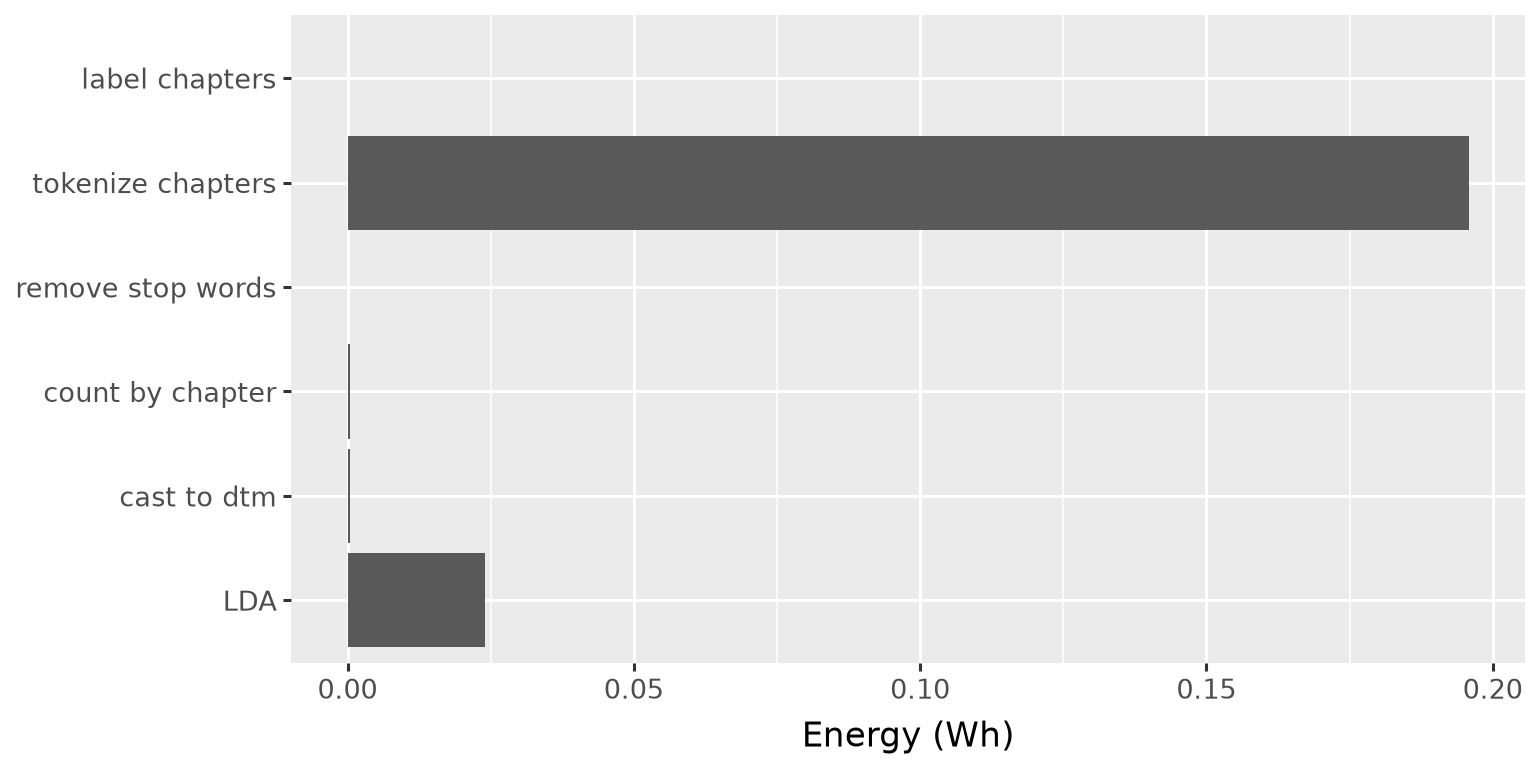

In [14]:
lda_plot = lda_steps.with_columns(
    label=pl.col("label").cast(pl.Enum(lda_steps["label"].reverse())),
    energy_wh=pl.col("energy_consumed") * 1000,
)

ggplot(lda_plot, aes("label", "energy_wh")) + geom_col() + coord_flip() + labs(
    x="", y="Energy (Wh)"
)

When an LDA is fit on larger data, with more topics, or with more fits to find
the optimal number of topics (k), these numbers increase. Yet they are hardly
noticeable compared to ever more complex fine-tuning of transformer models or
inference with large language models.

### Optimizing a Tokenizer

The tokenizing above uses NLTK’s word tokenizer, the standard choice, which
runs as Python code on each line of text. polars can split text into words
too, with a regular expression that runs in its Rust engine.
`unnest_tokens_fast()` does that: a word is a run of letters and digits,
with an apostrophe inside it kept (“don’t”):

In [15]:
def unnest_tokens_fast(data, column):
    """Split text into words, one row each, like tidytext's unnest_tokens().

    The text is lower-cased, and a word is a run of letters and digits,
    with an apostrophe inside it kept ("don't").
    """
    return (
        data
        .with_columns(
            pl.col(column)
            .str.to_lowercase()
            .str.extract_all(r"[\p{L}\p{N}]+(?:'[\p{L}]+)*").alias("word")
        )
        .drop(column)
        .explode("word")
        .drop_nulls("word")
    )

Which is faster, and by how much? Guessing is easy; measuring is better. Run
each tokenizer on the chapters five times, in turn, each run as a task of its
own:

In [16]:
tokenizers = {"nltk": unnest_tokens, "polars": unnest_tokens_fast}
times = 5

tracker = OfflineEmissionsTracker(project_name="tokenizer benchmark", **tracker_args)

rows = []
try:
    for i in range(1, times + 1):
        for name, tokenize in tokenizers.items():
            tracker.start_task(f"{name}_{i}")
            tokenize(chapters, "text")
            task = tracker.stop_task()
            rows.append({"tokenizer": name, "iter": i, **vars(task)})
finally:
    tracker.stop()

tokenizer_bench = pl.DataFrame(rows).with_columns(
    energy_wh=pl.col("energy_consumed") * 1000
)

tokenizer_bench.group_by("tokenizer", maintain_order=True).agg(
    duration_sec=pl.col("duration").median(),
    energy_wh=pl.col("energy_wh").median(),
)

tokenizer,duration_sec,energy_wh
str,f64,f64
"""nltk""",11.128701,0.268105
"""polars""",0.048769,0.001072


Each point is one run:

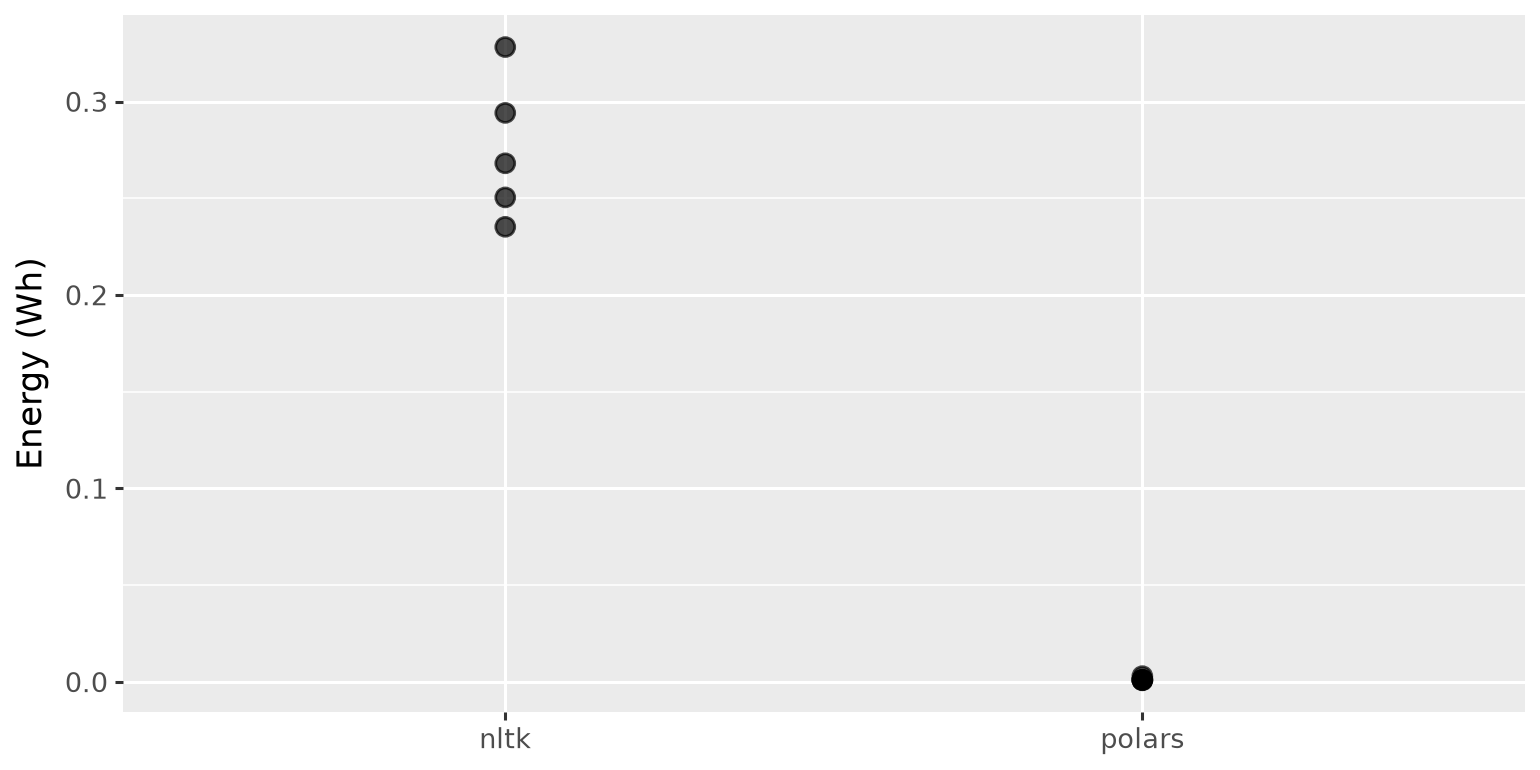

In [17]:
ggplot(tokenizer_bench, aes("tokenizer", "energy_wh")) + geom_point(
    size=3, alpha=0.7
) + labs(x="", y="Energy (Wh)")

The regular expression is about two orders of magnitude faster than NLTK,
and uses as much less energy. The two do not split text identically, though:
NLTK keeps “mr.” with its full stop and hyphenated words such as
“drawing-room” whole, which the regular expression splits apart. Whether
that difference is worth the energy is a choice for the analysis at hand;
a benchmark turns the choice from a guess into a measurement. It is also
cheap: a few runs of each candidate, before a pipeline is run on a large
corpus, can save far more energy than they use.

## Next Steps

The tutorial continues in two more notebooks, each of which runs on its own:

- `sentiment_tracking`: measure and benchmark dictionary sentiment analysis,
  written with polars and with NLTK.
- `llm_tracking`: estimate the energy and emissions of sentiment analysis
  with a hosted large language model, using EcoLogits.

## Technical Details

See the [CodeCarbon documentation](https://mlco2.github.io/codecarbon/) and
the [EcoLogits documentation](https://ecologits.ai) for their methods, and
the [TidyCarbon repository](https://github.com/seankellyhp/Tidycarbon) for
the R version of this tutorial.

## References

Balluff, P., Ho, J. C., Gruber, J. B., Palicki, S., Palmer, A., et al. (2026). Newer, larger, better? A critique of the unreflective LLM adoption in communication research. *Political Communication*.

Bird, S., Klein, E., & Loper, E. (2009). *Natural language processing with Python: Analyzing text with the natural language toolkit*. O’Reilly Media.

Courty, B., Schmidt, V., Goyal-Kamal, Coutarel, M., Blanche, L., Feld, B., et al. (2026). *mlco2/codecarbon* (3.3.1). Zenodo. <https://doi.org/10.5281/zenodo.4658424>

Hamilton-Palicki, S., & Bravo, I. (2026). *tidycarbon: Tidy R wrapper for Python’s CodeCarbon emissions tracker*. <https://github.com/seankellyhp/Tidycarbon>

Hamilton-Palicki, S., Bravo, I., & Claessen, C. (2026). Don’t look up: Evaluating the tradeoff between performance and sustainability of text classification using open LLMs. *Social Science Computer Review*. <https://doi.org/10.1177/08944393261473230>

Luccioni, A. S., Jernite, Y., & Strubell, E. (2024). Power hungry processing: Watts driving the cost of AI deployment? *Proceedings of the 2024 ACM Conference on Fairness, Accountability, and Transparency*, 85–99. <https://doi.org/10.1145/3630106.3658542>

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, *12*, 2825–2830.

Rincé, S., & Banse, A. (2025). EcoLogits: Evaluating the environmental impacts of generative AI. *Journal of Open Source Software*, *10*(111), 7471. <https://doi.org/10.21105/joss.07471>

Silge, J., & Robinson, D. (2017). *Text mining with R: A tidy approach*. O’Reilly Media. <https://www.tidytextmining.com>

Wolf, T., Debut, L., Sanh, V., Chaumond, J., Delangue, C., Moi, A., Cistac, P., Rault, T., Louf, R., Funtowicz, M., Davison, J., Shleifer, S., Platen, P. von, Ma, C., Jernite, Y., Plu, J., Xu, C., Le Scao, T., Gugger, S., … Rush, A. M. (2020). Transformers: State-of-the-art natural language processing. *Proceedings of the 2020 Conference on Empirical Methods in Natural Language Processing: System Demonstrations*, 38–45. <https://doi.org/10.18653/v1/2020.emnlp-demos.6>

## Disclaimer

This method is intended for academic research; ensure legality and ethics
when processing chat data.

## Contact Details